# Farm Animal Activity Recognition — Version 3 (final)

**One YOLO detector, four behaviours that are visible in a single image:** standing, lying, foraging, drinking.

Rumination is no longer a main class. It is jaw movement over time and cannot be seen reliably in one frame; in CBVD-5 it is almost always given *together* with a posture (e.g. lying + ruminating), which caused the largest error of Iteration 1. A ruminating cow is now counted under its posture. Rumination is left as future work.

**Data**
1. **CBVD-5** (Kaggle `fandaoerji/cbvd-5cow-behavior-video-dataset`), same split by video as Iteration 1, so the test videos are identical.
2. **Beef Cattle Behavior Data Set** (Kaggle `lucyfirst/beef-cattle-behavior-data-set`) detection images, with the per-cow behaviour labels published by the Cattle-YOLO project (downloaded automatically from GitHub; 766 images).

**Kaggle settings:** add both datasets, GPU on, Internet on. Optional: add the Iteration 1 `best.pt` and set `OLD_BASELINE_PT` for a side-by-side test.

In [1]:
!nvidia-smi
!pip install -q -U ultralytics lap

Mon Nov  9 02:34:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 0. Configuration

In [2]:
import os, re, json, time, random, shutil, zipfile, urllib.request, warnings
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np, pandas as pd, cv2, yaml
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPyImage
from sklearn.model_selection import StratifiedGroupKFold
warnings.filterwarnings("ignore")
SEED = 42; random.seed(SEED); np.random.seed(SEED)

INPUT_ROOT = "/kaggle/input"
CBVD_ROOT, BEEF_ROOT = None, None                 # None = auto-detect
WORK = Path("/kaggle/working"); MODELS_DIR = WORK / "models"; RUNS = WORK / "runs"
for d in (MODELS_DIR, RUNS): d.mkdir(parents=True, exist_ok=True)

CLASSES = ["standing", "lying", "foraging", "drinking"]          # final classes
C2I = {c: i for i, c in enumerate(CLASSES)}
KEYWORDS = {"standing": ["stand"], "lying": ["lying", "lie", "lay", "recumb"], "foraging": ["forag", "eat", "feed", "graz"],
            "drinking": ["drink"], "rumination": ["rumin", "chew"], "walking": ["walk"]}
OLD_PRIORITY = ["drinking", "foraging", "rumination", "lying", "standing"]   # Iteration 1 rule (only to rebuild its split)
WALKING_AS = "standing"                                              # beef labels have 'walking'; a walking cow is upright

# Cattle-YOLO behaviour labels for the Kaggle beef images (CC0 images; labels published on GitHub)
BEEF_LABELS_URL = "https://github.com/classmateju/Cattle-Yolo/raw/main/cattle_pose_reproduce.zip"
BEEF_LABELS_DIR = None        # or a folder that already holds image*.txt and classes.txt (if Internet is off)

DET_MODELS = ["yolo11s.pt", "yolov8s.pt", "yolo11m.pt"]   # compared; finished models are reused
EPOCHS, PATIENCE, IMGSZ, BATCH = 150, 40, 640, 16
DRINKING_REPEAT = 2           # training images that contain drinking are listed this many times (mild oversampling)

OLD_BASELINE_PT = None        # e.g. "/kaggle/input/iteration1-model/best.pt"
OLD_REPORTED_F1 = {"standing": 0.691, "lying": 0.476, "foraging": 0.833, "drinking": 0.585, "rumination": 0.601}
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}; VID_EXT = {".mp4", ".avi", ".mov", ".mkv"}

## 1. Locate the datasets

In [3]:
def list_dirs(root, max_depth=5, max_children=400):
    out, queue = [], [(Path(root), 0)]
    while queue:
        p, d = queue.pop(0)
        try: kids = [e for e in os.scandir(p) if e.is_dir()]
        except (PermissionError, FileNotFoundError): continue
        for k in kids:
            out.append(Path(k.path))
            if d + 1 < max_depth and len(kids) <= max_children: queue.append((Path(k.path), d + 1))
    return out

all_dirs = list_dirs(INPUT_ROOT)
def under(root): return [d for d in all_dirs if str(d).startswith(str(root))]

CBVD = Path(CBVD_ROOT) if CBVD_ROOT else next((d.parent for d in all_dirs if d.name.lower() == "annotations"
                                               and any("ava" in f.lower() for f in os.listdir(d))), None)
beefy = [d for d in all_dirs if "beef" in d.name.lower()]
BEEF = Path(BEEF_ROOT) if BEEF_ROOT else (min(beefy, key=lambda d: len(d.parts)) if beefy else None)
print("CBVD-5:", CBVD); print("Beef  :", BEEF)
assert CBVD is not None, "CBVD-5 not found: add it with 'Add Input'."

CBVD-5: /kaggle/input/datasets/fandaoerji/cbvd-5cow-behavior-video-dataset
Beef  : /kaggle/input/datasets/lucyfirst/beef-cattle-behavior-data-set


## 2. CBVD-5: labels, the same split as Iteration 1, and the new 4 classes

The split is rebuilt with exactly the first notebook's steps (same seed, same labels), so the **test videos are the same**. The printed table must show train 382 videos / 2,278 images, validation 81 / 480, test 74 / 441.
Then each cow gets one of the 4 classes: drinking, else foraging, else lying (including lying + ruminating), else standing.

In [4]:
def cls_from_name(name):
    low = name.lower(); hits = [c for c, kws in KEYWORDS.items() if any(k in low for k in kws)]
    return hits[0] if len(hits) == 1 else None

ann_dir = CBVD / "annotations"
text = next(p for p in ann_dir.iterdir() if ".pbtxt" in p.name).read_text()
aid2cls = {}
for block in re.findall(r"\{([^{}]*)\}", text):
    n = re.search(r'name\s*:\s*"([^"]+)"', block); i = re.search(r"\b(?:label_id|id)\s*:\s*(\d+)", block)
    if n and i and cls_from_name(n.group(1)): aid2cls[int(i.group(1))] = cls_from_name(n.group(1))
print("Action ids:", aid2cls)

frames = []
for p in sorted(ann_dir.glob("*.csv")):
    if "exclud" in p.name.lower(): continue
    d = pd.read_csv(p, header=None, dtype=str).iloc[:, :8]
    d.columns = ["video_id", "ts", "x1", "y1", "x2", "y2", "action_id", "entity_id"][:d.shape[1]]
    for c in ["ts", "x1", "y1", "x2", "y2", "action_id"]: d[c] = pd.to_numeric(d[c], errors="coerce")
    frames.append(d.dropna(subset=["ts", "x1", "y1", "x2", "y2", "action_id"]))
ann = pd.concat(frames, ignore_index=True)
ann["video_id"] = ann.video_id.str.strip(); ann["action_id"] = ann.action_id.astype(int); ann["ts"] = ann.ts.round(3)
ann = ann.drop_duplicates(subset=["video_id", "ts", "x1", "y1", "x2", "y2", "action_id"])
ann = ann[ann.action_id.isin(aid2cls)].copy(); ann["cls"] = ann.action_id.map(aid2cls)
for c in ["x1", "y1", "x2", "y2"]: ann[c + "_r"] = ann[c].round(3)
cb = (ann.groupby(["video_id", "ts", "x1_r", "y1_r", "x2_r", "y2_r"])["cls"].agg(lambda s: tuple(sorted(set(s)))).reset_index()
        .rename(columns={"cls": "labels", "x1_r": "x1", "y1_r": "y1", "x2_r": "x2", "y2_r": "y2"}))

lf_index = {}
for d in under(CBVD):
    if d.name.lower() == "labelframes":
        for f in os.scandir(d):
            if f.is_file() and f.name.lower().endswith(".jpg") and "_" in f.name:
                v, n = Path(f.name).stem.rsplit("_", 1)
                if n.isdigit(): lf_index[(v, int(n))] = f.path
cb["img"] = [lf_index.get((v, int(round(t)))) for v, t in zip(cb.video_id, cb.ts)]
cb = cb[cb.img.notna()].copy()
bad = (cb[["x1", "y1", "x2", "y2"]] > 1.05).any(axis=1) | (cb[["x1", "y1", "x2", "y2"]] < -0.05).any(axis=1)
print("Broken boxes removed:", int(bad.sum())); cb = cb[~bad].copy()
for a, b in (("x1", "x2"), ("y1", "y2")):
    lo = cb[[a, b]].clip(0, 1).min(axis=1); hi = cb[[a, b]].clip(0, 1).max(axis=1); cb[a], cb[b] = lo, hi
cb = cb[((cb.x2 - cb.x1) >= 0.003) & ((cb.y2 - cb.y1) >= 0.003)].reset_index(drop=True)

# Iteration 1 split (uses its 5-class labels so the folds are identical)
old_lab = cb.labels.apply(lambda L: next(c for c in OLD_PRIORITY if c in L))
old_i = {c: i for i, c in enumerate(["standing", "lying", "foraging", "drinking", "rumination"])}
y, g = [old_i[c] for c in old_lab], list(cb.video_id); ns = min(20, len(set(g))); fold = {}
for f, (_, te) in enumerate(StratifiedGroupKFold(n_splits=ns, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y, g)):
    for i in te: fold[g[i]] = f
nt = round(ns * 0.15)
cb["split"] = ["test" if fold[v] < nt else "val" if fold[v] < 2 * nt else "train" for v in cb.video_id]

# new 4-class label
def four(labels):
    if "drinking" in labels: return "drinking"
    if "foraging" in labels: return "foraging"
    if "lying" in labels: return "lying"
    return "standing"
cb["cls4"] = cb.labels.apply(four)
tab = cb.groupby("split").agg(videos=("video_id", "nunique"), images=("img", "nunique"), boxes=("img", "size"))
display(tab.join(pd.crosstab(cb.split, cb.cls4)[CLASSES]).loc[["train", "val", "test"]])

Action ids: {1: 'standing', 2: 'lying', 3: 'foraging', 4: 'drinking', 5: 'rumination'}
Broken boxes removed: 2


,videos,images,boxes,standing,lying,foraging,drinking
split,,,,,,,
train,382,2278,18402,6962,6670,4236,534
val,81,480,3854,1338,1517,860,139
test,74,441,3064,1096,1285,612,71


## 3. Beef images with per-cow behaviour labels

The Cattle-YOLO labels (`walking, standing, eating, laying`) are matched to the Kaggle beef images by file name (`image123.txt` ↔ `image123.jpg`). The beef images keep the dataset's own train / val / test folders. As a check, each behaviour box is compared with the dataset's own *cow* box for the same image; images whose boxes don't line up are left out. Beef images without behaviour labels are not used, because their cows would count as background.

In [5]:
beef = pd.DataFrame()
if BEEF is not None:
    # 3a. behaviour labels
    lab_dir = Path(BEEF_LABELS_DIR) if BEEF_LABELS_DIR else None
    if lab_dir is None:
        zp = WORK / "cattle_yolo_labels.zip"
        if not zp.exists():
            if BEEF_LABELS_URL.startswith("http"): urllib.request.urlretrieve(BEEF_LABELS_URL, zp)
            else: shutil.copy(BEEF_LABELS_URL, zp)
        lab_dir = WORK / "cattle_yolo_labels"; lab_dir.mkdir(exist_ok=True)
        with zipfile.ZipFile(zp) as z:
            for m in z.namelist():
                nm = Path(m).name
                if "/labels/" in m and (nm.startswith("image") or nm == "classes.txt") and nm.endswith(".txt"):
                    (lab_dir / nm).write_bytes(z.read(m))
    names = [l.strip() for l in (lab_dir / "classes.txt").read_text().splitlines() if l.strip()]
    id2cls = {}
    for i, n in enumerate(names):
        c = cls_from_name(n); id2cls[i] = WALKING_AS if c == "walking" else c
    print("Beef label classes:", dict(enumerate(names)), "->", id2cls)

    # 3b. Kaggle images and their 'cow' boxes
    img_dirs = sorted({p for pat in ("images", "*/images", "*/*/images") for p in BEEF.glob(pat) if p.is_dir()})
    print("Image folders:", [str(p.relative_to(BEEF)) for p in img_dirs])
    imgs = {p.stem: p for d in img_dirs for p in d.rglob("*") if p.suffix.lower() in IMG_EXT}

    def read_yolo(path):
        rows = []
        for line in open(path):
            v = line.split()
            if len(v) >= 5:
                c, xc, yc, w, h = int(float(v[0])), *map(float, v[1:5]); rows.append((c, xc - w/2, yc - h/2, xc + w/2, yc + h/2))
        return rows

    def iou(a, b):
        x1, y1, x2, y2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
        inter = max(0, x2 - x1) * max(0, y2 - y1)
        return inter / ((a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter + 1e-9)

    rows, skipped = [], Counter()
    for lf in sorted(lab_dir.glob("image*.txt")):
        stem = lf.stem
        if stem not in imgs: skipped["image not in Kaggle data"] += 1; continue
        beh = [(id2cls.get(c), x1, y1, x2, y2) for c, x1, y1, x2, y2 in read_yolo(lf)]
        beh = [b for b in beh if b[0] in C2I]
        if not beh: skipped["no usable boxes"] += 1; continue
        cow_lab = Path(str(imgs[stem]).replace("/images/", "/labels/")).with_suffix(".txt")
        if cow_lab.exists():
            cows = [r[1:] for r in read_yolo(cow_lab)]
            match = np.median([max([iou(b[1:], c) for c in cows] or [0]) for b in beh])
            if match < 0.5: skipped["boxes do not line up"] += 1; continue
        rows.append({"img": str(imgs[stem]), "boxes": beh, "main": Counter(b[0] for b in beh).most_common(1)[0][0]})
    beef = pd.DataFrame(rows)
    print(f"Beef images used: {len(beef)}   skipped: {dict(skipped)}")

    # 3c. use the dataset's own train / val / test folders (official split)
    def folder_split(p):
        parts = [x.lower() for x in Path(p).parts]
        return "val" if any(x in ("val", "valid", "validation") for x in parts) else "test" if "test" in parts else "train"
    if len(beef):
        beef["split"] = [folder_split(p) for p in beef.img]
        cnt = Counter((s, b[0]) for s, bx in zip(beef.split, beef.boxes) for b in bx)
        display(pd.DataFrame({s: {c: cnt[(s, c)] for c in CLASSES} for s in ["train", "val", "test"]}).T
                .assign(images=beef.split.value_counts()))

Beef label classes: {0: 'walking', 1: 'standing', 2: 'eating', 3: 'laying'} -> {0: 'standing', 1: 'standing', 2: 'foraging', 3: 'lying'}
Image folders: ['Target detection dataset/Target detection dataset/images']
Beef images used: 766   skipped: {}


,standing,lying,foraging,drinking,images
train,851,1476,846,0,592
val,249,127,171,0,111
test,149,82,70,0,63


## 4. Build the YOLO dataset (4 classes)

In [6]:
DS = WORK / "det4"
if DS.exists(): shutil.rmtree(DS)
lists = defaultdict(list)
def put(src, boxes, split, source, stem):
    (DS / "images" / split).mkdir(parents=True, exist_ok=True); (DS / "labels" / split).mkdir(parents=True, exist_ok=True)
    dst = DS / "images" / split / (stem + Path(src).suffix.lower())
    if not dst.exists(): os.symlink(src, dst)
    with open(DS / "labels" / split / (stem + ".txt"), "w") as f:
        for c, x1, y1, x2, y2 in boxes:
            f.write(f"{C2I[c]} {(x1+x2)/2:.6f} {(y1+y2)/2:.6f} {x2-x1:.6f} {y2-y1:.6f}\n")
    reps = DRINKING_REPEAT if split == "train" and any(b[0] == "drinking" for b in boxes) else 1
    for _ in range(reps): lists[split].append(str(dst))
    lists[f"{split}_{source}"].append(str(dst))

for (v, t), g in cb.groupby(["video_id", "ts"]):
    put(g.img.iloc[0], list(zip(g.cls4, g.x1, g.y1, g.x2, g.y2)), g.split.iloc[0], "cbvd", f"cbvd_{v}_{t:g}".replace(".", "p"))
for i, r in beef.iterrows():
    put(r.img, r.boxes, r.split, "beef", f"beef_{Path(r.img).stem}")

def write_yaml(name, train, val, test):
    for k, items in (("train", train), ("val", val), ("test", test)): (DS / f"{name}_{k}.txt").write_text("\n".join(items))
    yaml.safe_dump({"path": str(DS), "train": f"{name}_train.txt", "val": f"{name}_val.txt", "test": f"{name}_test.txt",
                    "nc": len(CLASSES), "names": dict(enumerate(CLASSES))}, open(DS / f"{name}.yaml", "w"), sort_keys=False)
    return DS / f"{name}.yaml"
YAML = write_yaml("all", lists["train"], lists["val"], lists["test"])
YAML_SRC = {s: write_yaml(s, lists["train"], lists[f"val_{s}"], lists[f"test_{s}"]) for s in ("cbvd", "beef") if lists[f"test_{s}"]}
print({k: len(v) for k, v in sorted(lists.items())})

{'test': 504, 'test_beef': 63, 'test_cbvd': 441, 'train': 3293, 'train_beef': 592, 'train_cbvd': 2278, 'val': 591, 'val_beef': 111, 'val_cbvd': 480}


## 5. Train and compare three detectors (YOLO11s, YOLOv8s, YOLO11m)

In [7]:
from ultralytics import YOLO
import torch
DEVICE = 0 if torch.cuda.is_available() else "cpu"

def train(weights):
    name = "det4_" + Path(weights).stem; best = MODELS_DIR / f"{name}.pt"
    if best.exists(): print("Reusing", best); return best, RUNS / "detect" / name
    m = YOLO(weights)
    m.train(data=str(YAML), epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ, batch=BATCH, device=DEVICE, project=str(RUNS / "detect"),
            name=name, exist_ok=True, seed=SEED, cos_lr=True, close_mosaic=15, fliplr=0.5, flipud=0.0, amp=True, plots=True, workers=4)
    run = Path(m.trainer.save_dir); shutil.copy2(run / "weights" / "best.pt", best); return best, run

runs = {Path(w).stem: train(w) for w in DET_MODELS}

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/det4/all.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, f

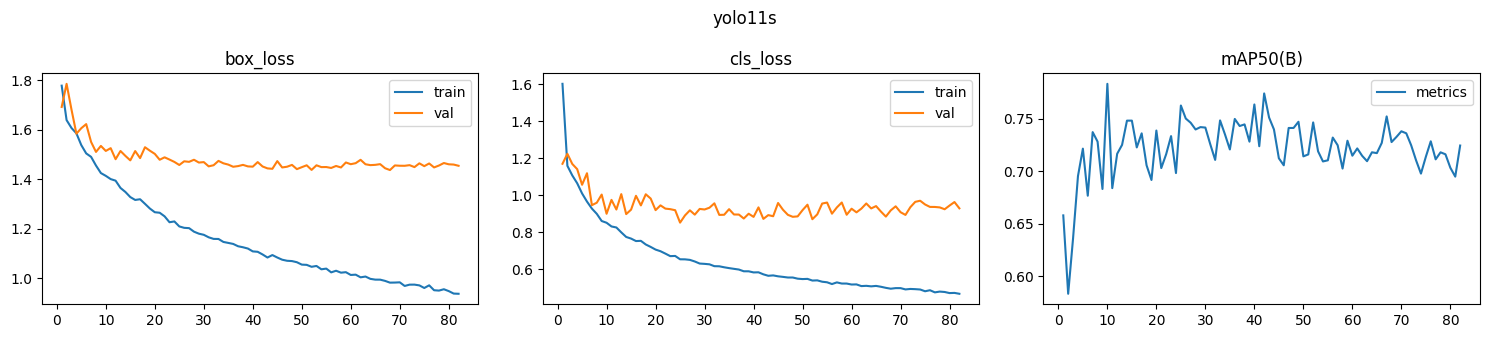

yolo11s -> OVERFITTING after epoch 25 (best epoch kept)


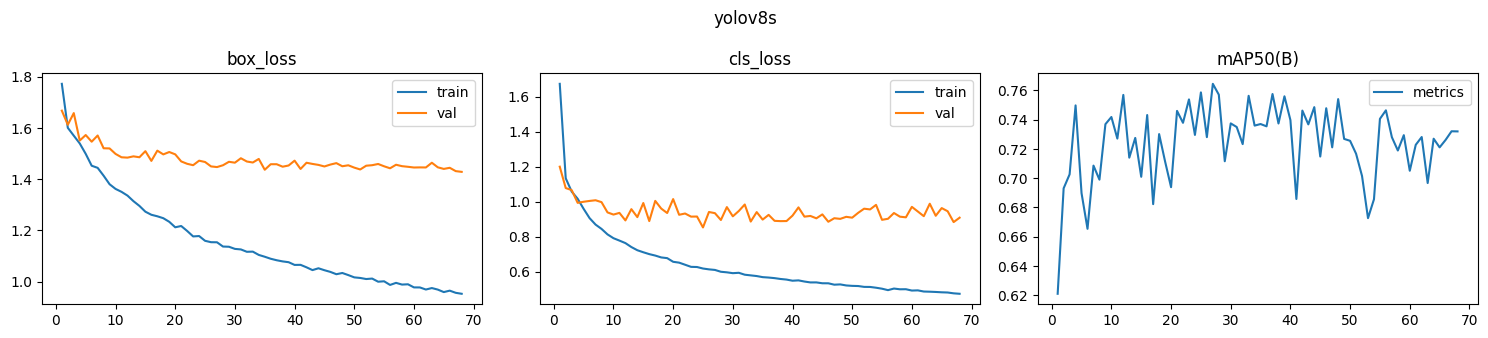

yolov8s -> OVERFITTING after epoch 25 (best epoch kept)


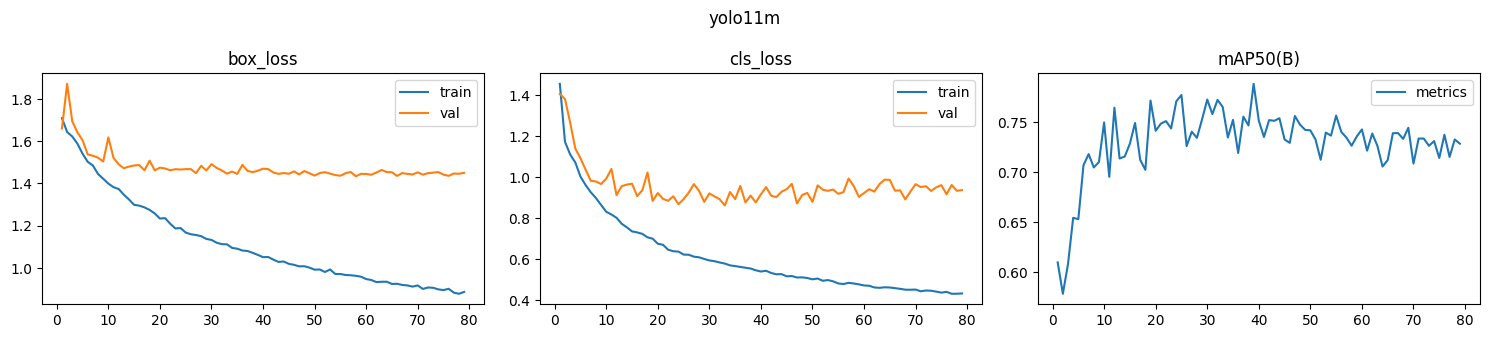

yolo11m -> OVERFITTING after epoch 33 (best epoch kept)


In [8]:
# ---- learning curves and fit check ----
def fit_diagnosis(df, tc, vc):
    t, v = df[tc].values, df[vc].values; n = len(t); k = max(3, n // 10)
    t_slope = (t[-k:].mean() - t[-2*k:-k].mean()) / (abs(t[-2*k:-k].mean()) + 1e-9); vb = int(np.argmin(v))
    if t_slope < -0.02 and vb >= n - k: return "UNDERFITTING: still improving at the end"
    if vb < n - 2 * k and v[-1] > v.min() * 1.05: return f"OVERFITTING after epoch {vb + 1} (best epoch kept)"
    return "GOOD FIT"

fit = {}
for name, (best, run) in runs.items():
    df = pd.read_csv(run / "results.csv"); df.columns = [c.strip() for c in df.columns]
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
    for a, (tc, vc) in zip(ax, [("train/box_loss", "val/box_loss"), ("train/cls_loss", "val/cls_loss"), ("metrics/mAP50(B)", None)]):
        a.plot(df.epoch, df[tc], label=tc.split("/")[0])
        if vc: a.plot(df.epoch, df[vc], label="val")
        a.set_title(tc.split("/")[1]); a.legend()
    fig.suptitle(name); plt.tight_layout(); plt.show()
    fit[name] = fit_diagnosis(df, "train/cls_loss", "val/cls_loss"); print(name, "->", fit[name])

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.2 ms, read: 16.2±7.2 MB/s, size: 1499.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/working/det4/labels/test... 504 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 504/504 31.0it/s 16.2s
val: New cache created: /kaggle/working/det4/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 2.3it/s 14.2s
                   all        504       3365      0.757      0.755      0.769      0.425
Speed: 0.6ms preprocess, 6.4ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /kaggle/working/runs/detect/yolo11s_test_all
Ultralytics 8.4.208 🚀 Python-3.13.16 torch

,model,test set,mAP50,mAP50-95,macro-F1,FP per image,conf,fit,AP50 standing,AP50 lying,AP50 foraging,AP50 drinking
0,yolo11s,all,0.769,0.425,0.721,0.577,0.45,OVERFITTING after epoch 25 (best epoch kept),0.751,0.885,0.808,0.633
1,yolo11s,cbvd,0.762,0.403,0.719,0.594,0.45,OVERFITTING after epoch 25 (best epoch kept),0.726,0.875,0.813,0.633
2,yolo11s,beef,0.918,0.746,0.610,0.460,0.45,OVERFITTING after epoch 25 (best epoch kept),0.910,0.995,0.850,NaN
3,yolov8s,all,0.785,0.436,0.728,0.964,0.40,OVERFITTING after epoch 25 (best epoch kept),0.761,0.893,0.863,0.622
4,yolov8s,cbvd,0.774,0.414,0.724,1.016,0.40,OVERFITTING after epoch 25 (best epoch kept),0.736,0.882,0.857,0.622
5,yolov8s,beef,0.927,0.749,0.635,0.619,0.40,OVERFITTING after epoch 25 (best epoch kept),0.923,0.995,0.864,NaN
6,yolo11m,all,0.786,0.446,0.705,0.623,0.45,OVERFITTING after epoch 33 (best epoch kept),0.743,0.900,0.862,0.638
7,yolo11m,cbvd,0.778,0.424,0.702,0.655,0.45,OVERFITTING after epoch 33 (best epoch kept),0.721,0.887,0.865,0.638
8,yolo11m,beef,0.909,0.733,0.620,0.413,0.45,OVERFITTING after epoch 33 (best epoch kept),0.889,0.995,0.842,NaN


Best model: yolo11m

yolo11m on all test set


,precision,recall,f1,cows
standing,0.791,0.629,0.701,1245.0
lying,0.903,0.835,0.867,1367.0
foraging,0.748,0.874,0.806,682.0
drinking,0.565,0.366,0.444,71.0



yolo11m on cbvd test set


,precision,recall,f1,cows
standing,0.784,0.609,0.685,1096.0
lying,0.896,0.824,0.859,1285.0
foraging,0.772,0.877,0.821,612.0
drinking,0.565,0.366,0.444,71.0



yolo11m on beef test set


,precision,recall,f1,cows
standing,0.835,0.779,0.806,149.0
lying,1.000,1.000,1.000,82.0
foraging,0.569,0.829,0.674,70.0
drinking,0.000,0.000,0.000,0.0


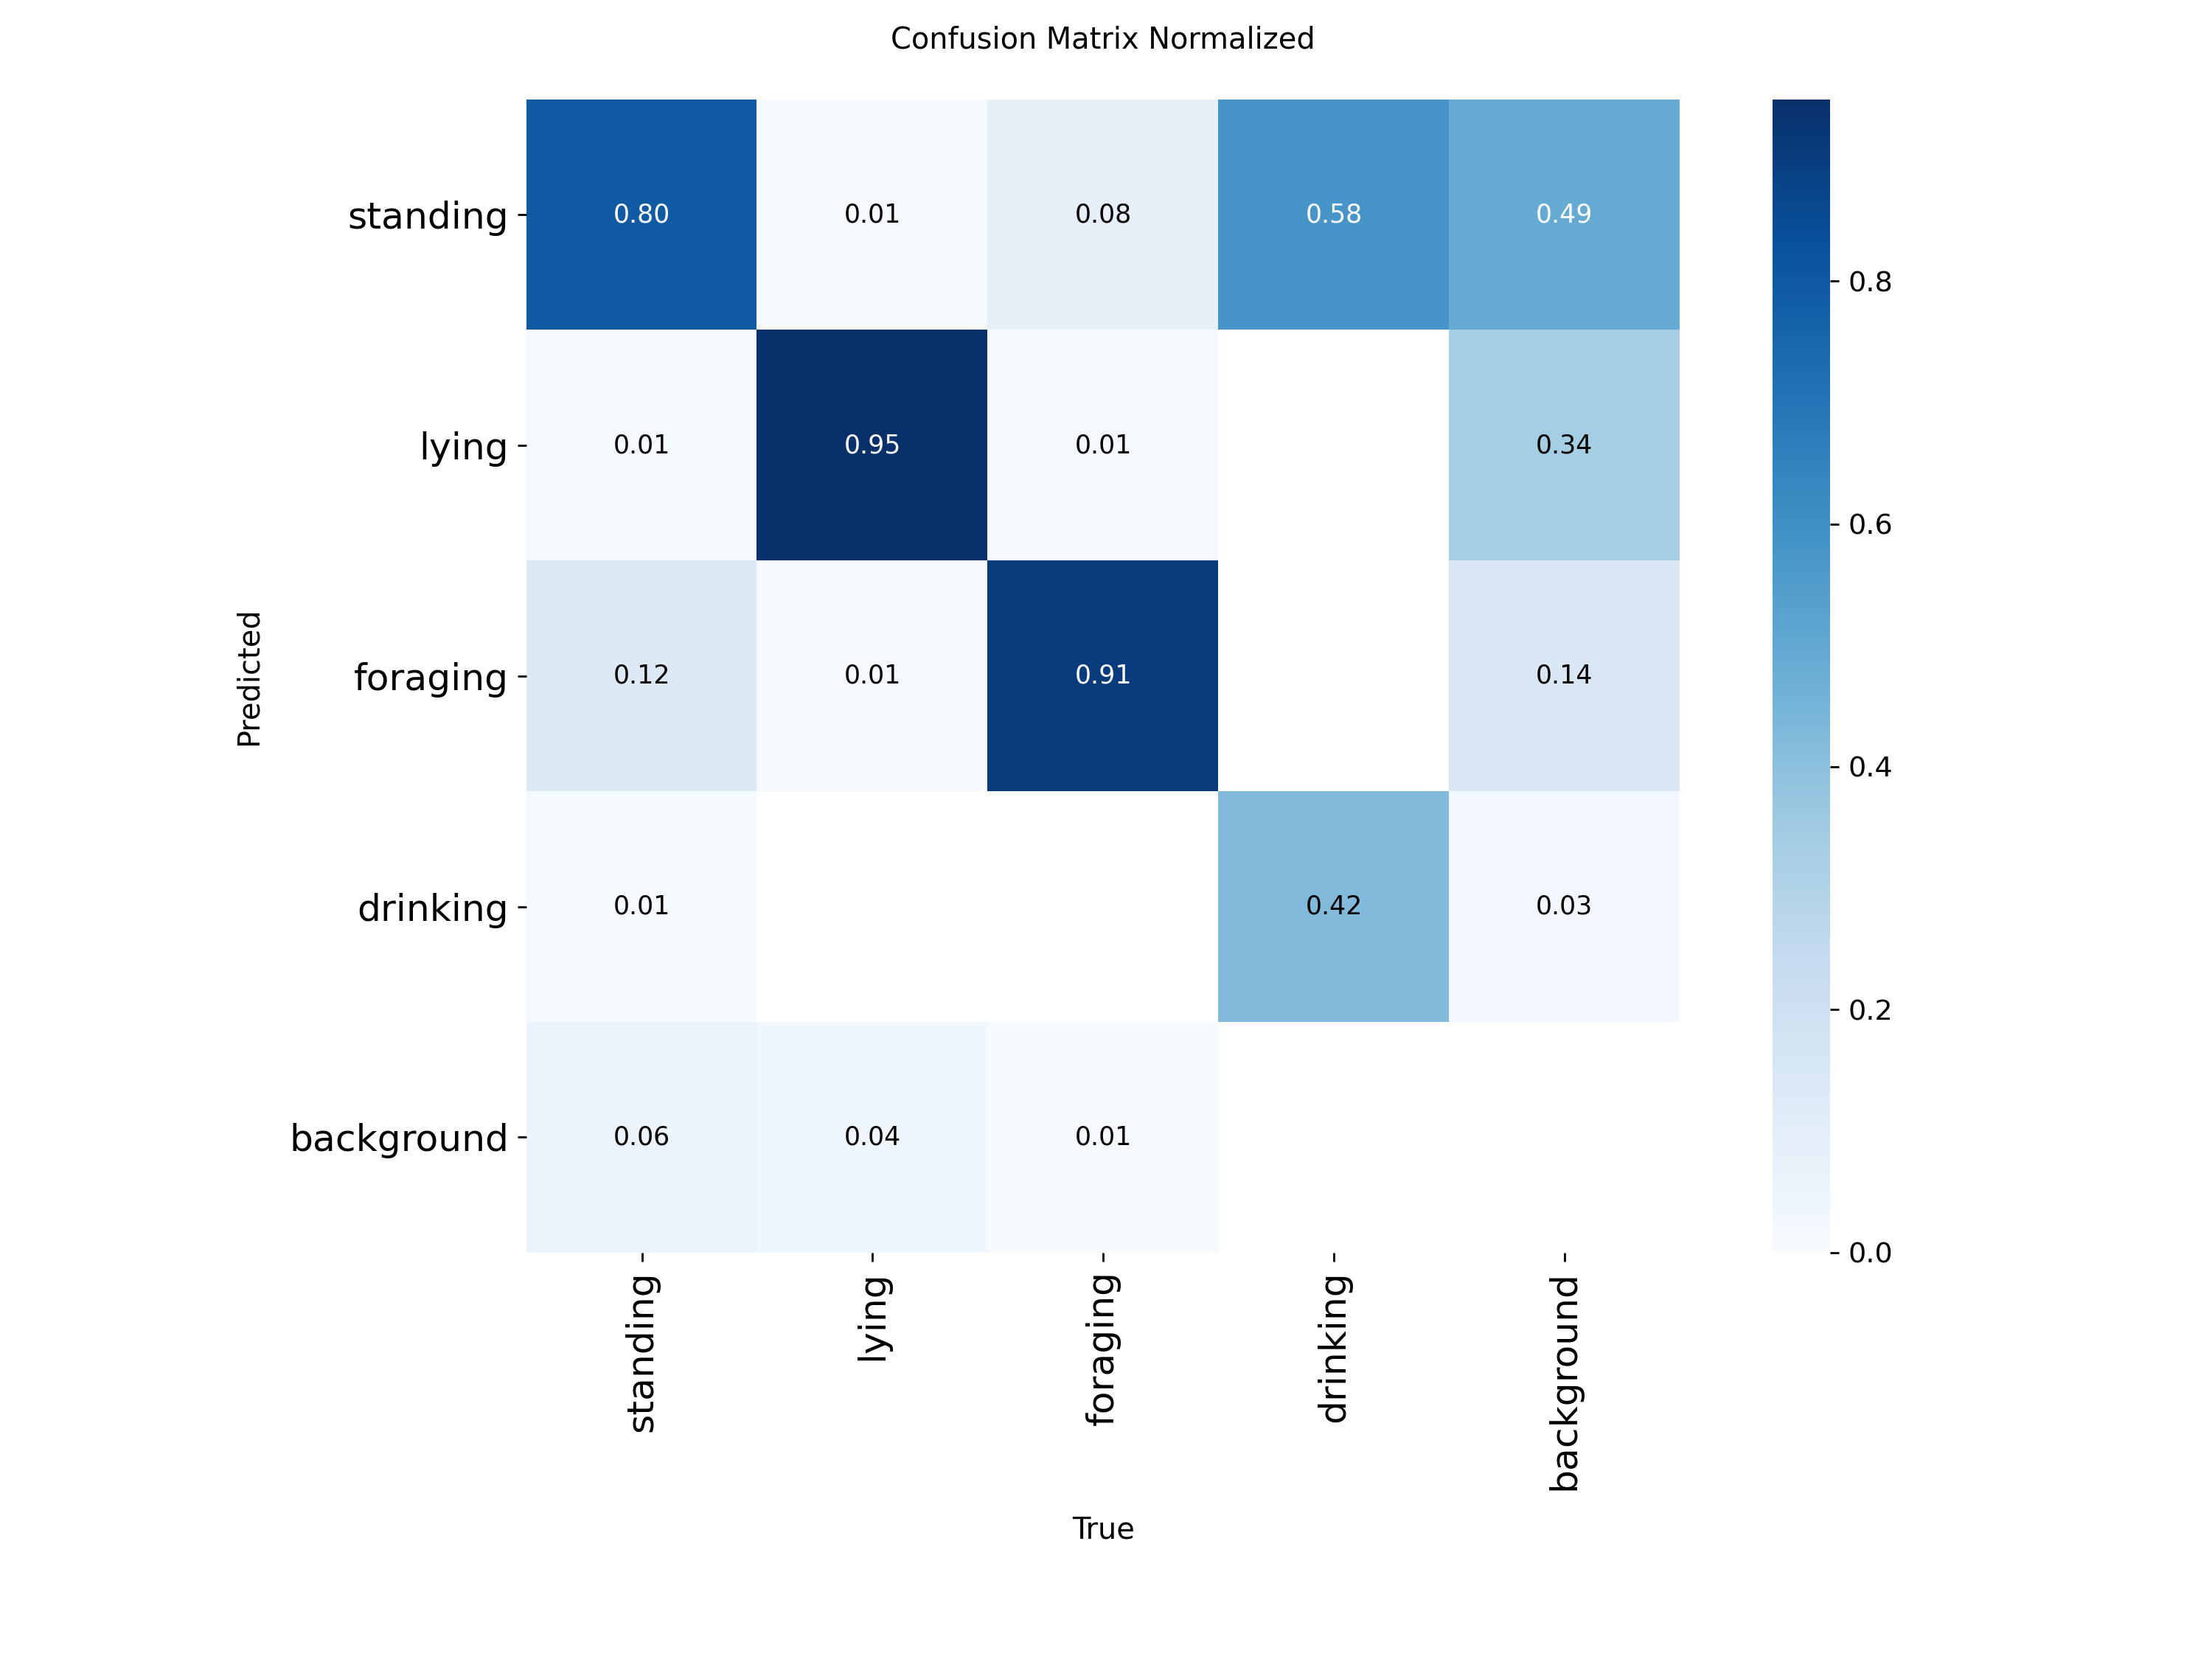

In [9]:
# ---- test results: per class, per dataset; false positives at a threshold chosen on validation ----
def iou_m(a, b):
    if not len(a) or not len(b): return np.zeros((len(a), len(b)))
    a, b = np.asarray(a, float), np.asarray(b, float)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None); ar = lambda r: (r[:, 2]-r[:, 0]) * (r[:, 3]-r[:, 1])
    return inter / (ar(a)[:, None] + ar(b)[None, :] - inter + 1e-9)

def match(pred, gt, thr=0.5):
    # pred: [(box, score, cls)], gt: [(box, cls)] -> list of (pred_cls or None, gt_cls or None)
    M = iou_m([p[0] for p in pred], [x[0] for x in gt]); used_g, pairs = set(), []
    for i in np.argsort([-p[1] for p in pred]):
        if M.shape[1] == 0: break
        row = M[i].copy(); row[list(used_g)] = -1; j = int(np.argmax(row))
        if row[j] >= thr: pairs.append((i, j)); used_g.add(j)
    up = {i for i, _ in pairs}
    return [(pred[i][2], gt[j][1]) for i, j in pairs] + [(pred[i][2], None) for i in range(len(pred)) if i not in up] + \
           [(None, gt[j][1]) for j in range(len(gt)) if j not in used_g]

def gt_of(img):
    lab = Path(str(img).replace("/images/", "/labels/")).with_suffix(".txt"); out = []
    for line in open(lab):
        c, xc, yc, w, h = line.split()[:5]; xc, yc, w, h = map(float, (xc, yc, w, h))
        out.append(((xc - w/2, yc - h/2, xc + w/2, yc + h/2), CLASSES[int(c)]))
    return out

def preds_of(model, paths, conf=0.01, names=None, mapper=None):
    out = {}
    for i in range(0, len(paths), 16):
        for p, r in zip(paths[i:i+16], model.predict(paths[i:i+16], conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)):
            cl = [(names or model.names)[int(k)] for k in r.boxes.cls.cpu().numpy()]
            if mapper: cl = [mapper(c) for c in cl]
            out[p] = [(b, s, c) for b, s, c in zip(r.boxes.xyxyn.cpu().numpy().tolist(), r.boxes.conf.cpu().numpy().tolist(), cl) if c]
    return out

def scores(recs, n_img):
    rows = {}
    for c in CLASSES:
        tp = sum(p == c and g == c for p, g in recs); fp = sum(p == c and g != c for p, g in recs); fn = sum(g == c and p != c for p, g in recs)
        P, R = tp / (tp + fp + 1e-9), tp / (tp + fn + 1e-9)
        rows[c] = {"precision": P, "recall": R, "f1": 2*P*R/(P+R+1e-9), "cows": tp + fn}
    df = pd.DataFrame(rows).T
    extra = {"macro-F1": df.f1.mean(), "FP per image (no cow there)": sum(p is not None and g is None for p, g in recs) / max(1, n_img)}
    return df, extra

def pick_conf(pr, paths):
    best = (0.25, -1)
    for c in np.arange(0.1, 0.85, 0.05):
        recs = []
        for p in paths: recs += match([x for x in pr[p] if x[1] >= c], gt_of(p))
        f = scores(recs, len(paths))[0].f1.mean()
        if f > best[1]: best = (float(c), f)
    return best[0]

summary, per_class = [], {}
for name, (best, _) in runs.items():
    m = YOLO(str(best)); val_paths = sorted(set(lists["val"]))
    conf = pick_conf(preds_of(m, val_paths), val_paths)
    for src, yml in [("all", YAML)] + list(YAML_SRC.items()):
        v = m.val(data=str(yml), split="test", imgsz=IMGSZ, batch=BATCH, device=DEVICE, project=str(RUNS / "detect"),
                  name=f"{name}_test_{src}", exist_ok=True, plots=True, verbose=False)
        paths = sorted(set((DS / f"{src}_test.txt").read_text().split()))
        pr = preds_of(m, paths, conf=conf); recs = []
        for p in paths: recs += match(pr[p], gt_of(p))
        df, ex = scores(recs, len(paths)); per_class[(name, src)] = df
        ap = {CLASSES[int(c)]: v.box.class_result(i)[2] for i, c in enumerate(v.box.ap_class_index)}
        summary.append({"model": name, "test set": src, "mAP50": v.box.map50, "mAP50-95": v.box.map, "macro-F1": ex["macro-F1"],
                        "FP per image": ex["FP per image (no cow there)"], "conf": conf, "fit": fit.get(name, ""),
                        **{f"AP50 {c}": ap.get(c, np.nan) for c in CLASSES}})
summary = pd.DataFrame(summary); display(summary.round(3)); summary.to_csv(WORK / "results_detectors.csv", index=False)
BEST = summary[summary["test set"] == "all"].sort_values("mAP50", ascending=False).model.iloc[0]
BEST_PT, BEST_CONF = runs[BEST][0], summary[(summary.model == BEST)].conf.iloc[0]
print("Best model:", BEST)
for src in ["all", "cbvd", "beef"]:
    if (BEST, src) in per_class: print(f"\n{BEST} on {src} test set"); display(per_class[(BEST, src)].round(3))
for f in ["confusion_matrix_normalized.png"]:
    p = RUNS / "detect" / f"{BEST}_test_all" / f
    if p.exists(): display(IPyImage(filename=str(p), width=650))

## 6. Same test videos as Iteration 1 (fair comparison)

Both models run on the CBVD-5 test keyframes and are scored with the same rule (a box must find the cow, IoU ≥ 0.5, **and** have the right behaviour). Iteration 1 predicts 5 classes; its *rumination* is counted as *lying*, because most ruminating cows in CBVD-5 are lying. Each model uses the threshold that is best for it on the validation videos.

In [10]:
comp = {}
cb_test = sorted(set(lists["test_cbvd"])); cb_val = sorted(set(lists["val_cbvd"]))
newm = YOLO(str(BEST_PT)); pr = preds_of(newm, cb_test, conf=BEST_CONF); recs = []
for p in cb_test: recs += match(pr[p], gt_of(p))
comp["Iteration 3 (this notebook)"] = scores(recs, len(cb_test))
if OLD_BASELINE_PT and Path(OLD_BASELINE_PT).exists():
    old = YOLO(OLD_BASELINE_PT)
    to4 = lambda c: "lying" if cls_from_name(c) == "rumination" else cls_from_name(c)
    c_old = pick_conf(preds_of(old, cb_val, mapper=to4), cb_val)
    pr = preds_of(old, cb_test, conf=c_old, mapper=to4); recs = []
    for p in cb_test: recs += match(pr[p], gt_of(p))
    comp["Iteration 1 (old model, same test)"] = scores(recs, len(cb_test))
table = pd.DataFrame({k: v[0].f1 for k, v in comp.items()})
table.loc["macro-F1"] = [v[1]["macro-F1"] for v in comp.values()]
table.loc["FP per image"] = [v[1]["FP per image (no cow there)"] for v in comp.values()]
display(table.round(3)); table.to_csv(WORK / "results_iteration_comparison.csv")
if not (OLD_BASELINE_PT and Path(OLD_BASELINE_PT).exists()):
    print("Iteration 1 reported F1 (5 classes, Ultralytics scoring, not the same rule):", OLD_REPORTED_F1)

,Iteration 3 (this notebook)
standing,0.685
lying,0.859
foraging,0.821
drinking,0.444
macro-F1,0.702
FP per image,0.655


Iteration 1 reported F1 (5 classes, Ultralytics scoring, not the same rule): {'standing': 0.691, 'lying': 0.476, 'foraging': 0.833, 'drinking': 0.585, 'rumination': 0.601}


## 7. Speed and demo video

In [11]:
def ms(fn, n):
    for _ in range(3): fn()
    if torch.cuda.is_available(): torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(n): fn()
    if torch.cuda.is_available(): torch.cuda.synchronize()
    return (time.perf_counter() - t) / n * 1000
frame = cv2.imread(cb_test[0]); speed = []
for dev in (["cuda", "cpu"] if torch.cuda.is_available() else ["cpu"]):
    t = ms(lambda: newm.predict(frame, imgsz=IMGSZ, device=0 if dev == "cuda" else "cpu", verbose=False), 30 if dev == "cuda" else 10)
    speed.append({"device": dev, "ms per frame": t, "FPS": 1000 / t})
speed = pd.DataFrame(speed); display(speed.round(1)); speed.to_csv(WORK / "results_speed.csv", index=False)

vid = next((p for d in (under(BEEF) if BEEF else []) if d.name.lower() == "videos" for p in sorted(d.glob("*.mp4"))), None)
if vid is not None:
    cap = cv2.VideoCapture(str(vid)); fps = cap.get(cv2.CAP_PROP_FPS) or 25; writer = None; n = 0; t0 = time.time()
    colors = [(176, 111, 46), (166, 90, 122), (50, 125, 46), (118, 118, 11)]
    while n < int(fps * 20):
        ok, f = cap.read()
        if not ok: break
        r = newm.track(f, persist=True, conf=BEST_CONF, imgsz=IMGSZ, device=DEVICE, tracker="bytetrack.yaml", verbose=False)[0]
        if r.boxes.id is not None:
            for b, c, tid in zip(r.boxes.xyxy.cpu().numpy().astype(int), r.boxes.cls.int().cpu().tolist(), r.boxes.id.int().cpu().tolist()):
                cv2.rectangle(f, tuple(b[:2]), tuple(b[2:]), colors[c], 2)
                cv2.putText(f, f"#{tid} {CLASSES[c]}", (b[0], max(18, b[1] - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, colors[c], 2)
        if writer is None: writer = cv2.VideoWriter(str(WORK / "demo.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), fps, (f.shape[1], f.shape[0]))
        writer.write(f); n += 1
    writer.release(); print(f"Demo: {n} frames at {n / (time.time() - t0):.1f} FPS -> {WORK / 'demo.mp4'}")

,device,ms per frame,FPS
0,cuda,24.8,40.3
1,cpu,347.5,2.9


Demo: 250 frames at 16.3 FPS -> /kaggle/working/demo.mp4


## 8. Save

In [12]:
shutil.copy2(BEST_PT, WORK / "best_4class.pt")
json.dump({"classes": CLASSES, "best_model": BEST, "conf": BEST_CONF, "detectors": summary.to_dict(orient="records"),
           "iteration_comparison": table.to_dict(), "speed": speed.to_dict(orient="records"), "fit": fit},
          open(WORK / "results_summary.json", "w"), indent=2, default=float)
print("Files: best_4class.pt, results_detectors.csv, results_iteration_comparison.csv, results_speed.csv, results_summary.json, demo.mp4")

Files: best_4class.pt, results_detectors.csv, results_iteration_comparison.csv, results_speed.csv, results_summary.json, demo.mp4
